# Regularization

**Objective:** Learn regularization with simple, step-by-step examples.

## How It Works
Regularization discourages overly large coefficients. Ridge and Lasso are common regularized linear models.

## 1. Import Libraries
We start with the standard tools used in many scikit-learn examples.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## 2. Load the Dataset
The CSV file is stored inside this topic folder so the notebook is self-contained.

In [2]:
data = pd.read_csv('datasets/student_scores.csv')
data.head()

,study_hours,practice_tests,attendance,previous_score,final_score
0,5.61,1,80.4,70.8,87.40
1,2.92,0,71.4,74.4,66.31
2,6.50,1,76.7,59.5,86.82
3,6.88,4,73.2,65.8,107.24
4,1.10,4,81.1,70.4,80.23


## 3. Explore the Data
Always inspect shape, columns, missing values, and basic statistics before modeling.

In [3]:
print(data.shape)
print(data.info())
data.describe()

(160, 5)
<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     160 non-null    float64
 1   practice_tests  160 non-null    int64  
 2   attendance      160 non-null    float64
 3   previous_score  160 non-null    float64
 4   final_score     160 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 6.4 KB
None


,study_hours,practice_tests,attendance,previous_score,final_score
count,160.000000,160.000000,160.000000,160.000000,160.000000
mean,4.872625,3.443750,82.316250,67.650625,96.177312
std,1.711900,2.438545,9.962306,12.077064,17.390839
min,0.740000,0.000000,56.300000,32.400000,57.370000
25%,3.710000,1.000000,75.900000,59.850000,83.182500
50%,4.865000,3.000000,82.900000,67.250000,97.125000
75%,6.007500,6.000000,89.350000,75.100000,110.207500
max,10.000000,7.000000,100.000000,99.200000,135.910000


In [4]:
data.isna().sum()

study_hours       0
practice_tests    0
attendance        0
previous_score    0
final_score       0
dtype: int64

## 4. Prepare Features and Target
`X` contains the input columns. `y` contains the answer we want to predict.

In [5]:
X = data.drop(columns=['final_score'])
y = data['final_score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(128, 4) (32, 4)


## 5. Train the Model
The model learns patterns from the training data.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge, Lasso

model = Ridge(alpha=1.0)
model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

## 6. Predict and Evaluate
For regression, common metrics are MAE, RMSE, and R-squared.

In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = (mean_squared_error(y_test, predictions) ** 0.5)
r2 = r2_score(y_test, predictions)

print('MAE:', round(mae, 2))
print('RMSE:', round(rmse, 2))
print('R2:', round(r2, 2))

MAE: 6.42
RMSE: 8.08
R2: 0.72


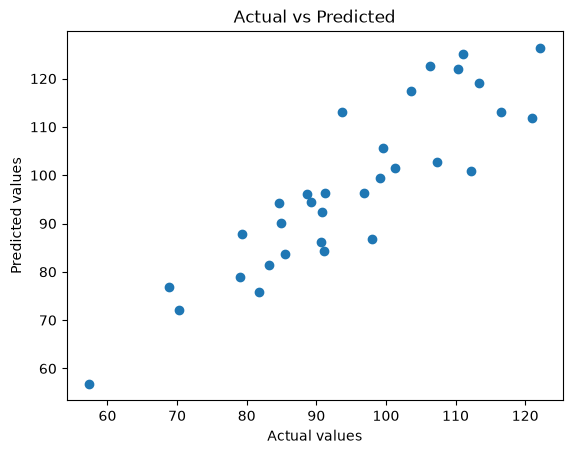

In [8]:
plt.scatter(y_test, predictions)
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted')
plt.show()

## Try This Yourself
- Change `test_size` from `0.2` to `0.3`.
- Print the first 10 predictions.
- Add or remove one feature and compare the metrics.

In [9]:
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_test)
print('Lasso R2:', r2_score(y_test, lasso_predictions))

Lasso R2: 0.7191079798869624
